In [1]:
import nltk 
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np
import random

In [2]:
import pandas as pd

df = pd.read_csv("hf://datasets/gsri-18/ISEAR-dataset-complete/ISEAR_dataset_complete.csv")
df = df.drop(columns=["Unnamed: 2"])
content = df["content"]
print(content.head())
emotions = df["emotion"].unique()

0    On days when I feel close to my partner and ot...
1    Every time I imagine that someone I love or I ...
2    When I had been obviously unjustly treated and...
3    When I think about the short time that we live...
4    At a gathering I found myself involuntarily si...
Name: content, dtype: object


In [3]:
# Dataset statistics before tokenization
emotions_unique = df["emotion"].unique()
print("Dataset statistics before tokenization for each unique emotion:")
print()
for emotion in emotions_unique:
    subset = df[df["emotion"] == emotion]
    N = len(subset["emotion"])
    print(f"{emotion} has {N} occurences, {round(N/len(df["emotion"]) * 100, 2)}%")
    average_length = subset["content"].str.len().mean()
    print(f"{emotion} has an average length of {average_length:.2f} characters")
    print()


Dataset statistics before tokenization for each unique emotion:

joy has 1092 occurences, 14.53%
joy has an average length of 103.14 characters

fear has 1076 occurences, 14.32%
fear has an average length of 123.96 characters

anger has 1079 occurences, 14.36%
anger has an average length of 130.65 characters

sadness has 1082 occurences, 14.4%
sadness has an average length of 103.93 characters

disgust has 1066 occurences, 14.18%
disgust has an average length of 114.61 characters

shame has 1071 occurences, 14.25%
shame has an average length of 116.73 characters

guilt has 1050 occurences, 13.97%
guilt has an average length of 124.89 characters



In [4]:
# Representation 1: Tokenization
tokens = []
for element in df["content"]:
    tokenized_sentence = word_tokenize(element)
    tokens.append(tokenized_sentence)
df["tokens"] = tokens


In [5]:
df.head(5)
# print avarage token length of sentence here.

,emotion,content,tokens
0,joy,On days when I feel close to my partner and ot...,"[On, days, when, I, feel, close, to, my, partn..."
1,fear,Every time I imagine that someone I love or I ...,"[Every, time, I, imagine, that, someone, I, lo..."
2,anger,When I had been obviously unjustly treated and...,"[When, I, had, been, obviously, unjustly, trea..."
3,sadness,When I think about the short time that we live...,"[When, I, think, about, the, short, time, that..."
4,disgust,At a gathering I found myself involuntarily si...,"[At, a, gathering, I, found, myself, involunta..."


In [6]:
# Representation 2: Bag of words
vectorizer = CountVectorizer(analyzer=lambda tokens: tokens)

bag_matrix = vectorizer.fit_transform(df["tokens"].tolist())

bag_df = pd.DataFrame(bag_matrix.toarray(),
                      columns=vectorizer.get_feature_names_out(),
                      index=df.index
)

print(bag_df.head(5))

   !  $  %  &  '  ''  '84  'cos  'd  'll  ...  yr.  yrs  yukky  zero  \
0  0  0  0  0  0   0    0     0   0    0  ...    0    0      0     0   
1  0  0  0  0  0   0    0     0   0    0  ...    0    0      0     0   
2  0  0  0  0  0   0    0     0   0    0  ...    0    0      0     0   
3  0  0  0  0  0   0    0     0   0    0  ...    0    0      0     0   
4  0  0  0  0  0   0    0     0   0    0  ...    0    0      0     0   

   zig-zagging  zip  zipper  zombies  zone  zoophiliac  
0            0    0       0        0     0           0  
1            0    0       0        0     0           0  
2            0    0       0        0     0           0  
3            0    0       0        0     0           0  
4            0    0       0        0     0           0  

[5 rows x 10175 columns]


In [7]:
# Representation 3: Bigrams

bigrams = []
for sentence in df["tokens"]:
    bigrams_per_sentence = []
    for i in range(len(sentence) - 1):
        bigram = sentence[i] + " " + sentence[i+1]
        bigrams_per_sentence.append(bigram)
    bigrams.append(bigrams_per_sentence)
df["bigrams"] = bigrams

In [8]:
# Representation 4: Trigrams

trigrams = []
for sentence in df["tokens"]:
    trigrams_per_sentence = []
    for i in range(len(sentence) - 2):
        trigram = sentence[i] + " " + sentence[i+1] + " " + sentence[i+2]
        trigrams_per_sentence.append(trigram)
    trigrams.append(trigrams_per_sentence)
df["trigrams"] = trigrams

In [9]:
print(df["trigrams"][0])

['On days when', 'days when I', 'when I feel', 'I feel close', 'feel close to', 'close to my', 'to my partner', 'my partner and', 'partner and other', 'and other friends', 'other friends .', 'friends . When', '. When I', 'When I feel', 'I feel at', 'feel at peace', 'at peace with', 'peace with myself', 'with myself and', 'myself and also', 'and also experience', 'also experience a', 'experience a close', 'a close contact', 'close contact with', 'contact with people', 'with people whom', 'people whom I', 'whom I regard', 'I regard greatly', 'regard greatly .']


In [10]:
# Architecture 1: Log-Linear
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
texts = df["content"].fillna("")
labels = sorted(df["emotion"].unique())
label_to_id = {label: i for i, label in enumerate(labels)}
y = df["emotion"].map(label_to_id)


token_indicator_model = Pipeline([
    ("features", CountVectorizer(
        tokenizer=word_tokenize,
        token_pattern=None,
        binary=True
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        C=1.0
    ))
])

# I chose for StratifiedKFold to keep the even emotion distrubition of the dataset in every fold
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

results = cross_validate(
    token_indicator_model,
    texts,
    y,
    cv=cv,
    scoring=["accuracy"],
    return_train_score=True
)

print("Validation accuracy:", results["test_accuracy"])
print("Mean accuracy:", results["test_accuracy"].mean())

Validation accuracy: [0.58976064 0.56420492 0.57884232 0.56886228 0.58150366]
Mean accuracy: 0.5766347623901134


In [13]:
# Cell to compare the three representations when used in logistic regression
models = {
    "token-indicator": Pipeline([
        ("features", CountVectorizer(
            tokenizer=word_tokenize,
            token_pattern=None,
            binary=True,
            ngram_range=(1, 1)
        )),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),
    "bag-of-words": Pipeline([
        ("features", CountVectorizer(
            tokenizer=word_tokenize,
            token_pattern=None,
            binary=False,
            ngram_range=(1, 1)
        )),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),
    "bigrams-only": Pipeline([
        ("features", CountVectorizer(
            tokenizer=word_tokenize,
            token_pattern=None,
            binary=False,
            ngram_range=(2, 2)
        )),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),
    "trigrams-only": Pipeline([
        ("features", CountVectorizer(
            tokenizer=word_tokenize,
            token_pattern=None,
            binary=False,
            ngram_range=(3, 3)
        )),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),
    "bigrams-and-trigrams": Pipeline([
        ("features", CountVectorizer(
            tokenizer=word_tokenize,
            token_pattern=None,
            binary=False,
            ngram_range=(2, 3)
        )),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),
    "unigrams-bigrams-and-trigrams": Pipeline([ # I'm testing if the scores improve when adding unigrams
            ("features", CountVectorizer(
                tokenizer=word_tokenize,
                token_pattern=None,
                binary=False,
                ngram_range=(1, 3)
            )),
            ("classifier", LogisticRegression(max_iter=2000))
        ])
}

train_scores = {}
scores = {}

for name, model in models.items():
    result = cross_validate(
        model,
        texts,
        y,
        cv=cv,
        scoring=["accuracy"],
        return_train_score=True
    )
    train_scores[name] = result["train_accuracy"]
    scores[name] = result["test_accuracy"]
    print(
        f"{name}: "
        f"train accuracy = {result['train_accuracy'].mean():.4f}, "
        f"test accuracy = {result['test_accuracy'].mean():.4f}, "
    )

token-indicator: train accuracy = 0.9492, test accuracy = 0.5766, 
bag-of-words: train accuracy = 0.9507, test accuracy = 0.5757, 
bigrams-only: train accuracy = 0.9976, test accuracy = 0.5231, 
trigrams-only: train accuracy = 0.9981, test accuracy = 0.4707, 
bigrams-and-trigrams: train accuracy = 0.9986, test accuracy = 0.5249, 
unigrams-bigrams-and-trigrams: train accuracy = 0.9986, test accuracy = 0.5805, 


A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)=0.0931 P(Tie)=0.8314 P(B wins)=0.0755 Effect Size=-0.09


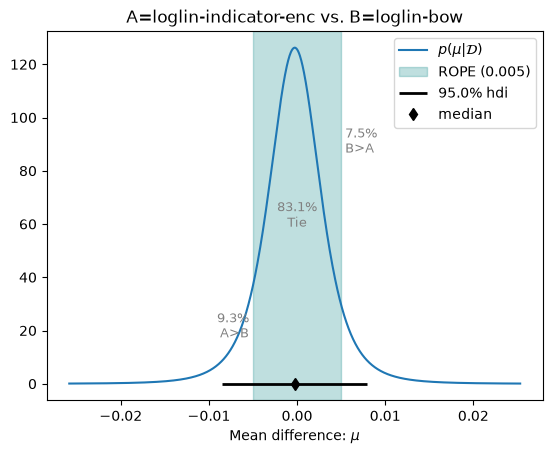

In [ ]:
import analysis

# First, a little helper, to gather all accuracies across runs and folds
def get_all_measurements_for(data, sys_name):
    return np.array([fold["metrics"][fold["best_epoch"]]["val_metrics"]["accuracy"] for fold in data[sys_name]])

posterior = analysis.BenavoliCorrelatedT(
    scores["token-indicator"],  # this will have shape [num_runs * num_folds]
    scores["bag-of-words"],  # this will have shape [num_runs * num_folds]
    names=["loglin-indicator-enc", "loglin-bow"]
)

p_a, p_tie, p_b = posterior.probs(0.005)
print(f"A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
_ = posterior.plot(0.005) 

In [ ]:
posterior = analysis.BenavoliCorrelatedT(
    scores["token-indicator"],  # this will have shape [num_runs * num_folds]
    scores["bigrams-and-trigrams"],  # this will have shape [num_runs * num_folds]
    names=["loglin-indicator-enc", "loglin-ngrams"]
)

p_a, p_tie, p_b = posterior.probs(0.005)
print(f"A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
_ = posterior.plot(0.005) 

In [ ]:
# classes and functions for mlp
import itertools
nltk.download("punkt_tab")

corpus = " ".join(df["content"].fillna("").astype(str))

vocab = sorted(set(word_tokenize(corpus)))
token_to_id = {token: i for i, token in enumerate(vocab)}

class Encoder:
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

def cross_validation_split(pairs, k, seed=0):
    """
    Shuffles a list of labelled texts and splits the result into k folds.
    
    pairs: lists of tuples (text, label)
    k: number of folds
    seed: for reproducible shuffling
    """
    
    # Shuffle the pairs
    random.seed(seed)
    pairs = list(pairs)
    ids = list(range(len(pairs)))
    random.shuffle(ids)

    # Split without coercing (text, int) tuples into a string array
    ids_parts = np.array_split(np.array(ids, dtype=object), k)
    
    # Create a dictionary to store the training and validation sets for each fold
    cross_validation_sets = {}
    for i in range(k):
        validation_set = [pairs[j] for j in ids_parts[i]] 
        training_ids = list(itertools.chain.from_iterable(part for k, part in enumerate(ids_parts) if k != i))
        training_set = [pairs[j] for j in training_ids]
        cross_validation_sets[i] = {
            "training": training_set, 
            "validation": validation_set, 
            'training_ids': training_ids,   # these are not often needed, but we return it just in case
            'validation_ids': ids_parts[i]  # these are not often needed, but we return it just in case
        }

    return cross_validation_sets

my_seeds = [0] # [0, 3, 5] # add more seeds here for multiple runs of cross validation, eg. [0, 3, 5]  
num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

# for seed in my_seeds:  
#     my_cross_validation_sets.append(
#         cross_validation_split(
#             # we pair the texts with their labels
#             pairs=list(zip(dataset["train"]["text"], dataset["train"]["label"])), 
#             k=num_folds,
#             seed=seed
#         )
#     )

class TokenIndicator(Encoder):
    def __init__(self, token_to_id):
        self.token_to_id = token_to_id

    def __len__(self):
        return len(self.token_to_id)

    def __call__(self, x: str) -> np.ndarray:
        vector = np.zeros(len(self), dtype=np.float32)

        for token in set(word_tokenize(x)):
            token_id = self.token_to_id.get(token)
            if token_id is not None:
                vector[token_id] = 1

        return vector
    
token_indicator_encoder = TokenIndicator(token_to_id)
doc_repr = token_indicator_encoder(corpus)

print(len(doc_repr))
print(doc_repr.sum())

[nltk_data] Downloading package punkt_tab to /home/colin/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


10176
10176.0


In [ ]:
import os
results_folder = "../Data/Results"
os.makedirs(results_folder, exist_ok=True)

In [ ]:
# Architecture 2: Single hidden layer MLP
import smlp

class CountVectorizerEncoder(Encoder):
    def __init__(self, vectorizer):
        self.vectorizer = vectorizer

    def __len__(self):
        return len(self.vectorizer.vocabulary_)

    def __call__(self, x: str) -> np.ndarray:
        return self.vectorizer.transform([x]).toarray().ravel()

labels = sorted(df["emotion"].unique())
pairs = [(content, labels.index(emotion)) for content, emotion in zip(df["content"], df["emotion"])]
cv = cross_validation_split(pairs, k=num_folds, seed=0)

# Settings for encoders for token indicator, BOW and unigrams + trigrams (capped due to memory issues).
encoder_configs = {
    "token-indicator": {
        "binary": True,
        "ngram_range": (1, 1),
    },
    "bag-of-words": {
        "binary": False,
        "ngram_range": (1, 1),
    },
    "bigrams-and-trigrams": {
        "binary": False,
        "ngram_range": (1, 2),
        "max_features": 50000
    },
}

results = {name: [] for name in encoder_configs}
encoder_accuracy = {}
# For each encoder run the model with hidden dim of 128 with cross validation.
for encoder_name, config in encoder_configs.items():
    mean_accuracy = []
    for fold in cv:
        print(encoder_name)
        training = cv[fold]["training"]
        validation = cv[fold]["validation"]

        vectorizer = CountVectorizer(
            tokenizer=word_tokenize,
            token_pattern=None,
            **config,
        )
        print("Fitting vectorizer")
        vectorizer.fit([content for content, label in training])
        print("Vocabulary size:", len(vectorizer.vocabulary_))
        print("Training MLP")
        encoder = CountVectorizerEncoder(vectorizer)

        metrics, best_epoch, best_pred = smlp.train_neural_network_model(
            training,
            validation,
            num_classes=len(labels),
            encoder=encoder,
            save_to=f"{results_folder}/mlp_{encoder_name}_{fold}_test",
            num_epochs=10,
        )

        results[encoder_name].append(
                    {
                        "metrics": metrics,
                        "best_epoch": best_epoch,
                        "best_pred": best_pred,
                    })

        best_val_acc_this_fold = max(epoch_data["val_metrics"]["accuracy"] for epoch_data in metrics)
        mean_accuracy.append(best_val_acc_this_fold)
    encoder_accuracy[f"{encoder_name}"] = np.mean(mean_accuracy)
print(mean_accuracy)


token-indicator
Fitting vectorizer
Vocabulary size: 8343
Training MLP
Transforming documents...
Document transformation done! Time taken: 2.975 seconds
Dataloader done! Time taken: 0.353 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

/home/colin/Downloads/nlp1-student-main/NLP-Classification-Project/Code/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:249.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/home/colin/Downloads/nlp1-student-main/NLP-Classification-Project/Code/smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:916.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 1.7952 | train acc: 0.4105 | val loss: 1.5609 | val acc: 0.5293
Epoch 02 | train loss: 1.1818 | train acc: 0.6647 | val loss: 1.2318 | val acc: 0.5851
Epoch 03 | train loss: 0.7673 | train acc: 0.7841 | val loss: 1.1655 | val acc: 0.5904
Epoch 04 | train loss: 0.5403 | train acc: 0.8576 | val loss: 1.1740 | val acc: 0.5924
Epoch 05 | train loss: 0.3995 | train acc: 0.8979 | val loss: 1.2242 | val acc: 0.5805
Epoch 06 | train loss: 0.3043 | train acc: 0.9250 | val loss: 1.2876 | val acc: 0.5851
Epoch 07 | train loss: 0.2361 | train acc: 0.9454 | val loss: 1.3621 | val acc: 0.5725
Epoch 08 | train loss: 0.1855 | train acc: 0.9614 | val loss: 1.4395 | val acc: 0.5711
Epoch 09 | train loss: 0.1531 | train acc: 0.9689 | val loss: 1.5144 | val acc: 0.5698
Epoch 10 | train loss: 0.1256 | train acc: 0.9746 | val loss: 1.5887 | val acc: 0.5725
Training done! Time taken: 12.638 seconds
token-indicator
Fitting vectorizer
Vocabulary size: 8399
Training MLP
Transforming docum

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.7918 | train acc: 0.4071 | val loss: 1.5460 | val acc: 0.5349
Epoch 02 | train loss: 1.1825 | train acc: 0.6637 | val loss: 1.2225 | val acc: 0.5902
Epoch 03 | train loss: 0.7686 | train acc: 0.7888 | val loss: 1.1596 | val acc: 0.5961
Epoch 04 | train loss: 0.5407 | train acc: 0.8571 | val loss: 1.1746 | val acc: 0.5921
Epoch 05 | train loss: 0.3995 | train acc: 0.9009 | val loss: 1.2119 | val acc: 0.5842
Epoch 06 | train loss: 0.3070 | train acc: 0.9263 | val loss: 1.2638 | val acc: 0.5908
Epoch 07 | train loss: 0.2402 | train acc: 0.9445 | val loss: 1.3230 | val acc: 0.5775
Epoch 08 | train loss: 0.1924 | train acc: 0.9591 | val loss: 1.3795 | val acc: 0.5729
Epoch 09 | train loss: 0.1570 | train acc: 0.9669 | val loss: 1.4453 | val acc: 0.5702
Epoch 10 | train loss: 0.1304 | train acc: 0.9769 | val loss: 1.5167 | val acc: 0.5689
Training done! Time taken: 11.077 seconds
token-indicator
Fitting vectorizer
Vocabulary size: 8413
Training MLP
Transforming docum

... (22 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.6915 | train acc: 0.4364 | val loss: 1.3642 | val acc: 0.5795
Epoch 02 | train loss: 0.7102 | train acc: 0.8482 | val loss: 1.1397 | val acc: 0.5981
Epoch 03 | train loss: 0.2325 | train acc: 0.9682 | val loss: 1.1437 | val acc: 0.6068
Epoch 04 | train loss: 0.1003 | train acc: 0.9902 | val loss: 1.1839 | val acc: 0.6001
Epoch 05 | train loss: 0.0542 | train acc: 0.9952 | val loss: 1.2259 | val acc: 0.5968
Epoch 06 | train loss: 0.0332 | train acc: 0.9967 | val loss: 1.2666 | val acc: 0.5895
Epoch 07 | train loss: 0.0234 | train acc: 0.9977 | val loss: 1.3081 | val acc: 0.5875
Epoch 08 | train loss: 0.0171 | train acc: 0.9983 | val loss: 1.3453 | val acc: 0.5868
Epoch 09 | train loss: 0.0132 | train acc: 0.9987 | val loss: 1.3744 | val acc: 0.5828
Epoch 10 | train loss: 0.0110 | train acc: 0.9983 | val loss: 1.4053 | val acc: 0.5822
Training done! Time taken: 52.379 seconds
bigrams-and-trigrams
Fitting vectorizer
Vocabulary size: 50000
Training MLP
Transforming

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.6856 | train acc: 0.4454 | val loss: 1.3396 | val acc: 0.5842
Epoch 02 | train loss: 0.7040 | train acc: 0.8457 | val loss: 1.1149 | val acc: 0.6068
Epoch 03 | train loss: 0.2355 | train acc: 0.9641 | val loss: 1.1037 | val acc: 0.6088
Epoch 04 | train loss: 0.1011 | train acc: 0.9890 | val loss: 1.1382 | val acc: 0.6075
Epoch 05 | train loss: 0.0542 | train acc: 0.9945 | val loss: 1.1711 | val acc: 0.6101
Epoch 06 | train loss: 0.0341 | train acc: 0.9970 | val loss: 1.2024 | val acc: 0.6134
Epoch 07 | train loss: 0.0246 | train acc: 0.9978 | val loss: 1.2336 | val acc: 0.6081
Epoch 08 | train loss: 0.0180 | train acc: 0.9977 | val loss: 1.2681 | val acc: 0.6101
Epoch 09 | train loss: 0.0146 | train acc: 0.9977 | val loss: 1.2922 | val acc: 0.6114
Epoch 10 | train loss: 0.0115 | train acc: 0.9982 | val loss: 1.3227 | val acc: 0.6015
Training done! Time taken: 52.362 seconds
[0.598404255319149, 0.6027944111776448, 0.5974717232202262, 0.6067864271457086, 0.613439

A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)=0.4231 P(Tie)=0.4849 P(B wins)=0.0920 Effect Size=-0.70


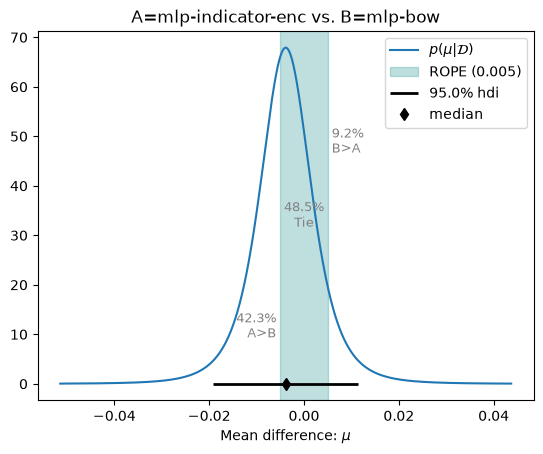

In [ ]:
import analysis

# First, a little helper, to gather all accuracies across runs and folds
def get_all_measurements_for(data, sys_name):
    return np.array([fold["metrics"][fold["best_epoch"]]["val_metrics"]["accuracy"] for fold in data[sys_name]])

posterior = analysis.BenavoliCorrelatedT(
    get_all_measurements_for(results, 'token-indicator'),  # this will have shape [num_runs * num_folds]
    get_all_measurements_for(results, 'bag-of-words'),  # this will have shape [num_runs * num_folds]
    names=["mlp-indicator-enc", "mlp-bow"]
)

p_a, p_tie, p_b = posterior.probs(0.005)
print(f"A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
_ = posterior.plot(0.005) 

In [ ]:
posterior = analysis.BenavoliCorrelatedT(
    get_all_measurements_for(results, 'token-indicator'),  # this will have shape [num_runs * num_folds]
    get_all_measurements_for(results, 'bigrams-and-trigrams'),  # this will have shape [num_runs * num_folds]
    names=["mlp-indicator-enc", "mlp-ngrams"]
)

p_a, p_tie, p_b = posterior.probs(0.005)
print(f"A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
_ = posterior.plot(0.005)

In [ ]:
# Architecture 3: Modified MLP - 2 hidden layers

import smlp_mod
class CountVectorizerEncoder(Encoder):
    def __init__(self, vectorizer):
        self.vectorizer = vectorizer

    def __len__(self):
        return len(self.vectorizer.vocabulary_)

    def __call__(self, x: str) -> np.ndarray:
        return self.vectorizer.transform([x]).toarray().ravel()

labels = sorted(df["emotion"].unique())
pairs = [(content, labels.index(emotion)) for content, emotion in zip(df["content"], df["emotion"])]
cv = cross_validation_split(pairs, k=num_folds, seed=0)

encoder_configs = {
    "token-indicator": {
        "binary": True,
        "ngram_range": (1, 1),
    },
    "bag-of-words": {
        "binary": False,
        "ngram_range": (1, 1),
    },
    "bigrams-and-trigrams": {
        "binary": False,
        "ngram_range": (1, 2),
        "max_features": 50000
    },
}

results = {name: [] for name in encoder_configs}

encoder_accuracy_mod = {}
for encoder_name, config in encoder_configs.items():
    mean_accuracy = []
    for fold in cv:
        print(encoder_name)
        training = cv[fold]["training"]
        validation = cv[fold]["validation"]

        vectorizer = CountVectorizer(
            tokenizer=word_tokenize,
            token_pattern=None,
            **config,
        )
        vectorizer.fit([content for content, label in training])
        print("Vocabulary size:", len(vectorizer.vocabulary_))
        encoder = CountVectorizerEncoder(vectorizer)

        metrics, best_epoch, best_pred = smlp_mod.train_neural_network_model(
            training,
            validation,
            num_classes=len(labels),
            encoder=encoder,
            save_to=f"{results_folder}/mlp_{encoder_name}_{fold}_test",
            num_epochs=10,
        )

        results[encoder_name].append(
            {
                "metrics": metrics,
                "best_epoch": best_epoch,
                "best_pred": best_pred,
            }
        )

        best_val_acc_this_fold = max(epoch_data["val_metrics"]["accuracy"] for epoch_data in metrics)
        mean_accuracy.append(best_val_acc_this_fold)
    encoder_accuracy_mod[f"{encoder_name}"] = np.mean(mean_accuracy)



token-indicator
Vocabulary size: 8343
Transforming documents...
Document transformation done! Time taken: 2.736 seconds
Dataloader done! Time taken: 0.325 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.7907 | train acc: 0.3525 | val loss: 1.4346 | val acc: 0.5106
Epoch 02 | train loss: 1.0171 | train acc: 0.6667 | val loss: 1.1991 | val acc: 0.5771
Epoch 03 | train loss: 0.5657 | train acc: 0.8240 | val loss: 1.2533 | val acc: 0.5824
Epoch 04 | train loss: 0.3343 | train acc: 0.9014 | val loss: 1.4141 | val acc: 0.5811
Epoch 05 | train loss: 0.2115 | train acc: 0.9419 | val loss: 1.5730 | val acc: 0.5751
Epoch 06 | train loss: 0.1357 | train acc: 0.9661 | val loss: 1.7835 | val acc: 0.5691
Epoch 07 | train loss: 0.0974 | train acc: 0.9741 | val loss: 1.9559 | val acc: 0.5585
Epoch 08 | train loss: 0.0705 | train acc: 0.9822 | val loss: 2.1058 | val acc: 0.5618
Epoch 09 | train loss: 0.0495 | train acc: 0.9904 | val loss: 2.2887 | val acc: 0.5559
Epoch 10 | train loss: 0.0396 | train acc: 0.9895 | val loss: 2.4396 | val acc: 0.5512
Training done! Time taken: 11.542 seconds
token-indicator
Vocabulary size: 8399
Transforming documents...
Document transformation 

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.7977 | train acc: 0.3308 | val loss: 1.4576 | val acc: 0.4950
Epoch 02 | train loss: 1.0434 | train acc: 0.6579 | val loss: 1.1821 | val acc: 0.5948
Epoch 03 | train loss: 0.5882 | train acc: 0.8176 | val loss: 1.2578 | val acc: 0.5868
Epoch 04 | train loss: 0.3568 | train acc: 0.8996 | val loss: 1.3709 | val acc: 0.5895
Epoch 05 | train loss: 0.2346 | train acc: 0.9361 | val loss: 1.5063 | val acc: 0.5802
Epoch 06 | train loss: 0.1506 | train acc: 0.9636 | val loss: 1.7202 | val acc: 0.5689
Epoch 07 | train loss: 0.1030 | train acc: 0.9747 | val loss: 1.8308 | val acc: 0.5615
Epoch 08 | train loss: 0.0786 | train acc: 0.9805 | val loss: 1.9817 | val acc: 0.5589
Epoch 09 | train loss: 0.0574 | train acc: 0.9872 | val loss: 2.1227 | val acc: 0.5549
Epoch 10 | train loss: 0.0452 | train acc: 0.9907 | val loss: 2.2428 | val acc: 0.5489
Training done! Time taken: 11.437 seconds
token-indicator
Vocabulary size: 8413
Transforming documents...
Document transformation 

  0%|          | 0/10 [00:00<?, ?it/s]

... (21 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.6891 | train acc: 0.4051 | val loss: 1.2873 | val acc: 0.5669
Epoch 02 | train loss: 0.5827 | train acc: 0.8403 | val loss: 1.2312 | val acc: 0.5842
Epoch 03 | train loss: 0.1138 | train acc: 0.9819 | val loss: 1.3737 | val acc: 0.5842
Epoch 04 | train loss: 0.0367 | train acc: 0.9942 | val loss: 1.4709 | val acc: 0.5862
Epoch 05 | train loss: 0.0178 | train acc: 0.9975 | val loss: 1.5956 | val acc: 0.5762
Epoch 06 | train loss: 0.0116 | train acc: 0.9980 | val loss: 1.6391 | val acc: 0.5802
Epoch 07 | train loss: 0.0118 | train acc: 0.9975 | val loss: 1.7317 | val acc: 0.5768
Epoch 08 | train loss: 0.0091 | train acc: 0.9980 | val loss: 1.7499 | val acc: 0.5828
Epoch 09 | train loss: 0.0089 | train acc: 0.9980 | val loss: 1.9224 | val acc: 0.5675
Epoch 10 | train loss: 0.0075 | train acc: 0.9985 | val loss: 1.8996 | val acc: 0.5702
Training done! Time taken: 54.111 seconds
bigrams-and-trigrams
Vocabulary size: 50000
Transforming documents...
Document transform

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.6989 | train acc: 0.4003 | val loss: 1.2783 | val acc: 0.5689
Epoch 02 | train loss: 0.5822 | train acc: 0.8352 | val loss: 1.1855 | val acc: 0.5915
Epoch 03 | train loss: 0.1136 | train acc: 0.9775 | val loss: 1.3015 | val acc: 0.6108
Epoch 04 | train loss: 0.0352 | train acc: 0.9947 | val loss: 1.4079 | val acc: 0.6015
Epoch 05 | train loss: 0.0181 | train acc: 0.9972 | val loss: 1.4869 | val acc: 0.6021
Epoch 06 | train loss: 0.0127 | train acc: 0.9977 | val loss: 1.5602 | val acc: 0.6021
Epoch 07 | train loss: 0.0081 | train acc: 0.9983 | val loss: 1.6230 | val acc: 0.5928
Epoch 08 | train loss: 0.0083 | train acc: 0.9983 | val loss: 1.6896 | val acc: 0.6035
Epoch 09 | train loss: 0.0064 | train acc: 0.9982 | val loss: 1.7017 | val acc: 0.5981
Epoch 10 | train loss: 0.0065 | train acc: 0.9983 | val loss: 1.8018 | val acc: 0.5975
Training done! Time taken: 53.437 seconds


In [ ]:
print(encoder_accuracy_mod)

{'token-indicator': np.float64(0.5874141787347291), 'bag-of-words': np.float64(0.5902089438144986), 'bigrams-and-trigrams': np.float64(0.5928687837091775)}


A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)=0.1363 P(Tie)=0.6358 P(B wins)=0.2279 Effect Size=0.22


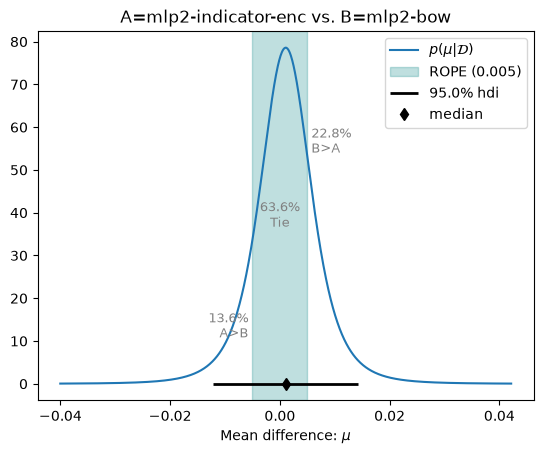

In [ ]:
posterior = analysis.BenavoliCorrelatedT(
    get_all_measurements_for(results, 'token-indicator'),  # this will have shape [num_runs * num_folds]
    get_all_measurements_for(results, 'bag-of-words'),  # this will have shape [num_runs * num_folds]
    names=["mlp2-indicator-enc", "mlp2-bow"]
)

p_a, p_tie, p_b = posterior.probs(0.005)
print(f"A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
_ = posterior.plot(0.005) 

A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)=0.0630 P(Tie)=0.5411 P(B wins)=0.3959 Effect Size=0.82


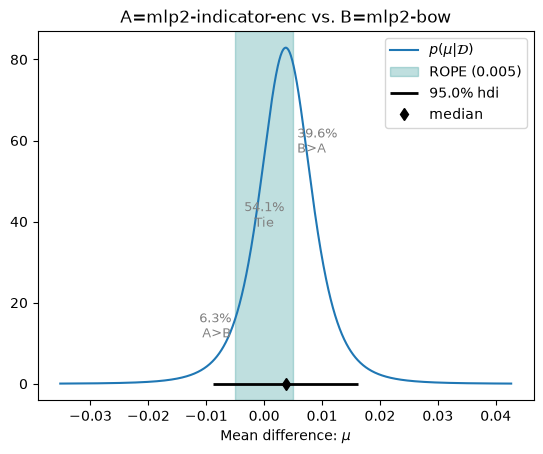

In [20]:
posterior = analysis.BenavoliCorrelatedT(
    get_all_measurements_for(results, 'token-indicator'),  # this will have shape [num_runs * num_folds]
    get_all_measurements_for(results, 'bigrams-and-trigrams'),  # this will have shape [num_runs * num_folds]
    names=["mlp2-indicator-enc", "mlp2-bow"]
)

p_a, p_tie, p_b = posterior.probs(0.005)
print(f"A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
_ = posterior.plot(0.005) 